In [17]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Uitzetten warnings voor opmaak
# warnings.filterwarnings('ignore')

# Opdracht 1: Voorspel Herseninfarct (Stroke Prediction)
**Competitie:** Predicting stroke 2026-27 | Kaggle  
**Teamnaam:**   Groep 4 <br>
**Teamleden & Kaggle Usernames:**  
- Kaman - [Kaggle Username 1]  
- Alex - [Kaggle Username 2]  
- Pablo - [Kaggle Username 3]  

## 1. Inleiding
In dit project werken we als junior data scientists bij *MedPredict*. Het doel is om een machine learning model te ontwikkelen dat op basis van demografische, leefstijl- en medische gegevens kan voorspellen of een patiënt een verhoogd risico loopt op een herseninfarct (stroke). Dit model zal zorgprofessionals ondersteunen bij preventie en gerichte opvolging.

In [18]:
train_df = pd.read_csv("train.csv")
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          33550 non-n

## 2. Data & Exploratieve Data Analyse (EDA)

### Uitleg van de kolommen
De dataset is al deels voorbewerkt. Categorische variabelen zijn omgezet naar dummy-kolommen (True/False).
- **id**: Uniek identificatienummer van de patiënt.
- **age**: Leeftijd van de patiënt in jaren.
- **hypertension**: 0 of 1 (of de patiënt hoge bloeddruk heeft).
- **heart_disease**: 0 of 1 (of de patiënt een hartziekte heeft).
- **avg_glucose_level**: Gemiddeld glucosegehalte in het bloed.
- **bmi**: Body Mass Index.
- **True/False kolommen (Dummies**: Gecodeerde categorische variabelen zoals `gender`, `ever_married`, `work_type`, `Residence_type`, en `smoking_status`.
- **stroke** (Target): 1 als de patiënt een herseninfarct heeft gehad, anders 0. (Ontbreekt in `test.csv`).

In [ ]:
class DataLoader:
    """Klasse voor het inladen en inspecteren van de data."""
    
    def __init__(self, train_path, test_path):
        self.train_path = train_path
        self.test_path = test_path
        
    def load_data(self):
        """Laadt de train en test datasets in."""
        # De CSV-bestanden bevatten een header-rij met kolomnamen,
        # dus we lezen ze in met de standaard header=0.
        self.train_df = pd.read_csv(self.train_path)
        self.test_df = pd.read_csv(self.test_path)
        
        # Converteer booleans (True/False) naar integers (1/0) voor Scikit-Learn
        bool_cols = self.train_df.select_dtypes(include=['bool']).columns
        for col in bool_cols:
            self.train_df[col] = self.train_df[col].astype(int)
            if col in self.test_df.columns:
                self.test_df[col] = self.test_df[col].astype(int)
                
        return self.train_df, self.test_df

# Inladen van de data
loader = DataLoader('train.csv', 'test.csv')
train_df, test_df = loader.load_data()

print("Train Data Shape:", train_df.shape)
print("Test Data Shape:", test_df.shape)
train_df.head()

Train Data Shape: (33550, 22)
Test Data Shape: (8388, 21)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,0,1,0,1,...,0,1,0,0,1,0,0,0,1,0
1,72295,75.0,1,0,215.17,48.0,1,0,0,0,...,0,0,1,0,1,0,0,1,0,0
2,26451,15.0,0,0,135.22,19.0,0,1,0,1,...,0,1,0,0,1,0,0,1,0,0
3,65210,47.0,0,0,64.89,28.2,0,1,0,0,...,0,0,1,0,0,1,0,1,0,0
4,69299,49.0,0,0,222.34,28.8,0,1,0,0,...,0,0,1,0,1,0,1,0,0,0


### 3.a. Minimale vereisten voor Machine Learning met Scikit-Learn
Scikit-Learn vereist dat alle inputvariabelen **numeriek** zijn en dat er **geen ontbrekende waarden (NaN)** zijn. 
- **Huidige status**: De dummy kolommen zijn al numeriek gemaakt (True/False naar 1/0). Echter, in de originele stroke dataset bevat de `bmi` kolom vaak ontbrekende waarden. Deze moeten we imputeren (bijv. met de mediaan).
- **Actie**: De `id` kolom is niet voorspellend en moet worden verwijderd om data leakage en ruis te voorkomen.

### 3.b. Datatypes en basisstatistieken

In [ ]:
def show_basic_stats(df):
    """Toont datatypes en statistieken."""
    print("--- Data Types ---")
    print(df.dtypes.value_counts())
    print("\n--- Basisstatistieken ---")
    display(df.describe())
    
    # Check voor missing values
    missing = df.isnull().sum()
    if missing.sum() > 0:
        print("\n--- Missing Values ---")
        print(missing[missing > 0])
    else:
        print("\nGeen missing values gevonden in de basisinspectie.")

show_basic_stats(train_df)

--- Data Types ---
int64      19
float64     3
Name: count, dtype: int64

--- Basisstatistieken ---


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,...,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.597079,0.402742,0.000179,0.361371,...,0.004203,0.574635,0.152787,0.144501,0.499970,0.500030,0.168733,0.375618,0.148048,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.490492,0.490457,0.013372,0.480405,...,0.064693,0.494406,0.359787,0.351602,0.500007,0.500007,0.374522,0.484289,0.355153,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,1.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,1.000000,1.000000,0.000000,1.000000,...,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Geen missing values gevonden in de basisinspectie.


### 3.c. Relaties tussen variabelen (Visualisaties)
We onderzoeken de relatie tussen de onafhankelijke variabelen en de target (`stroke`).

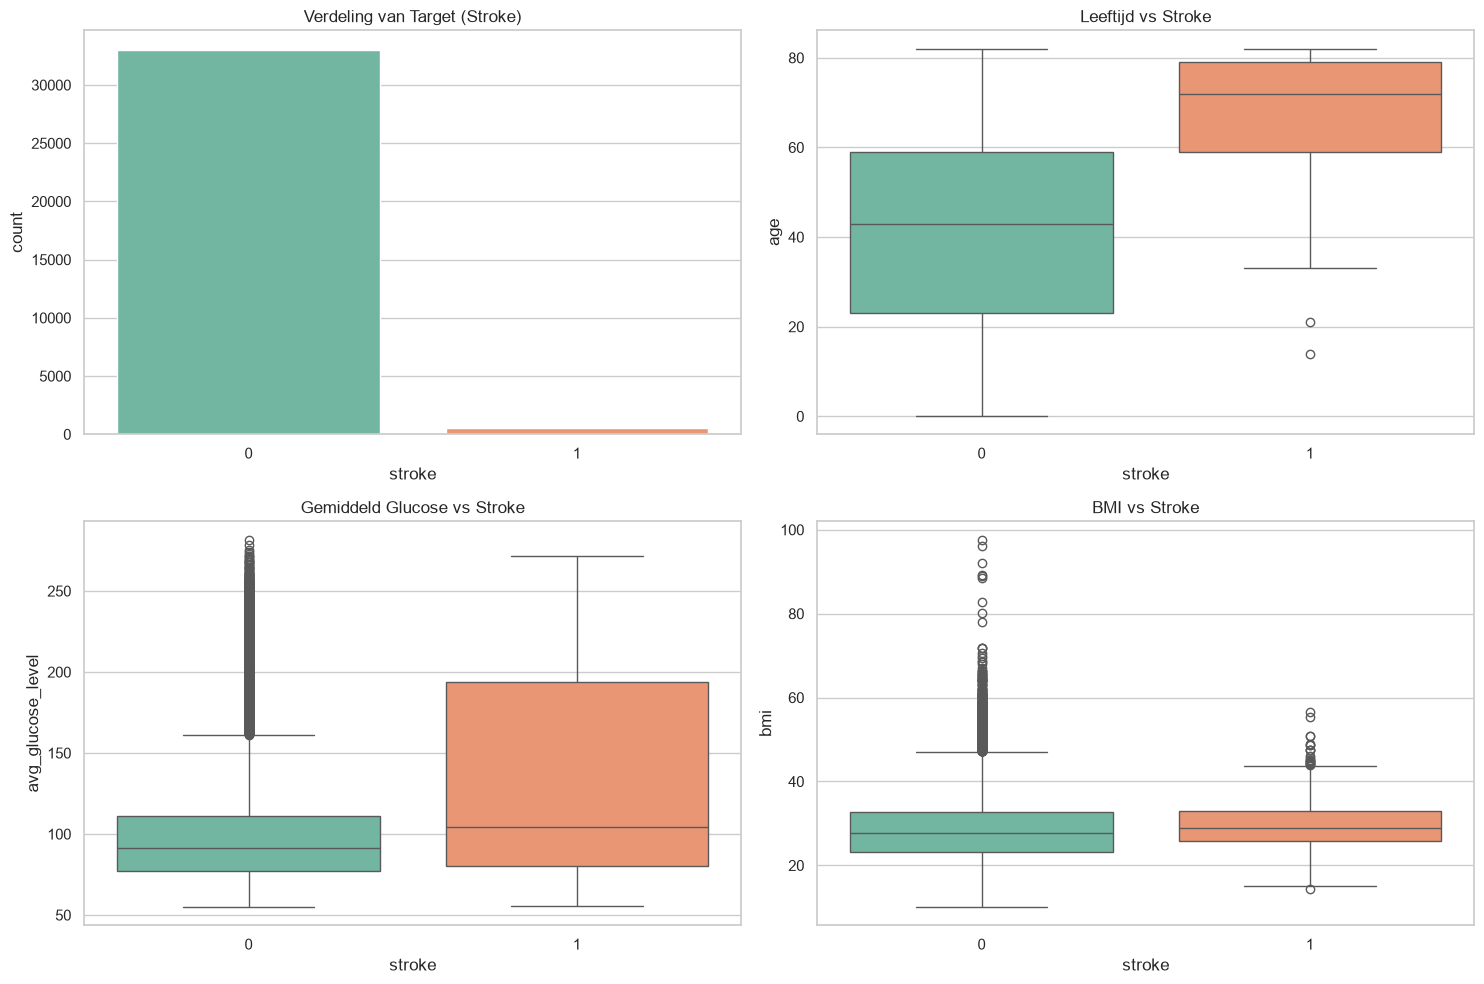

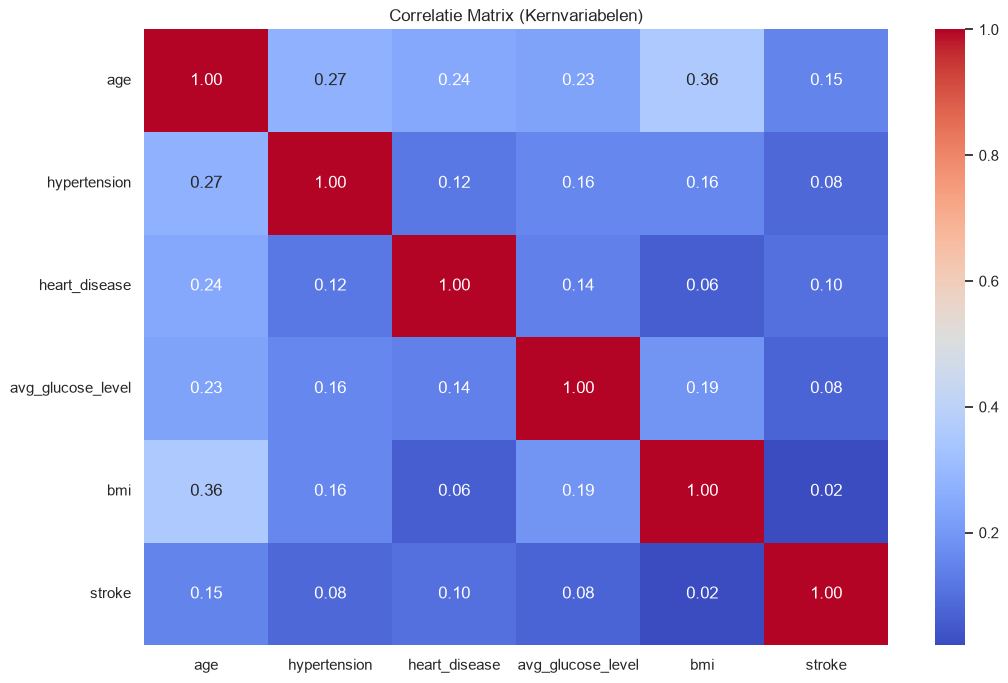

In [ ]:
def plot_eda(df):
    """Genereert EDA visualisaties."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # 1. Verdeling van Stroke (Imbalanced check)
    sns.countplot(x='stroke', data=df, ax=axes[0, 0], palette='Set2')
    axes[0, 0].set_title('Verdeling van Target (Stroke)')
    
    # 2. Leeftijd vs Stroke
    sns.boxplot(x='stroke', y='age', data=df, ax=axes[0, 1], palette='Set2')
    axes[0, 1].set_title('Leeftijd vs Stroke')
    
    # 3. Glucose vs Stroke
    sns.boxplot(x='stroke', y='avg_glucose_level', data=df, ax=axes[1, 0], palette='Set2')
    axes[1, 0].set_title('Gemiddeld Glucose vs Stroke')
    
    # 4. BMI vs Stroke
    sns.boxplot(x='stroke', y='bmi', data=df, ax=axes[1, 1], palette='Set2')
    axes[1, 1].set_title('BMI vs Stroke')
    
    plt.tight_layout()
    plt.show()

plot_eda(train_df)

# Correlatie matrix
plt.figure(figsize=(12, 8))
# We selecteren alleen de numerieke kernvariabelen voor de correlatie heatmap
num_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']
sns.heatmap(train_df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlatie Matrix (Kernvariabelen)')
plt.show()

### 3.d. Belangrijkste bevindingen van de EDA
1. **Zeer Imbalanced Dataset**: Het overgrote deel van de patiënten heeft geen stroke (0). Slechts een klein percentage heeft wel een stroke (1).
2. **Leeftijd**: Patiënten met een stroke zijn gemiddeld significant ouder.
3. **Glucose & BMI**: Er is een zichtbare correlatie; hogere glucosewaarden en extremere BMI-waarden lijken vaker voor te komen bij de stroke-groep.
4. **Hypertension & Heart Disease**: Deze binaire variabelen tonen een sterke positieve correlatie met de target.

### 4. Data Opschonen
We verwijderen de `id` kolom. Omdat Scikit-Learn niet goed omgaat met NaN's in sommige algoritmen, voegen we een imputatie-stap toe in onze modeling pipeline.

In [ ]:
def clean_data(train_df, test_df):
    """Verwijdert irrelevante kolommen."""
    X_train = train_df.drop(columns=['id', 'stroke'])
    y_train = train_df['stroke']
    
    X_test = test_df.drop(columns=['id'])
    
    return X_train, y_train, X_test

X_train, y_train, X_test = clean_data(train_df, test_df)
display(X_train.columns)

Index(['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi',
       'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No',
       'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked',
       'work_type_Private', 'work_type_Self-employed', 'work_type_children',
       'Residence_type_Rural', 'Residence_type_Urban',
       'smoking_status_formerly smoked', 'smoking_status_never smoked',
       'smoking_status_smokes'],
      dtype='str')